# Analysing Bruker timsTOF TDF (ion-mobility) data — on a Mac

TDF is the format timsTOF instruments write when ion mobility is on: PASEF, PRM-PASEF,
direct infusion with TIMS, and MALDI-TIMS imaging. Each *frame* holds hundreds of *scans*
(mobility bins), each scan a centroided peak list. Bruker's `tdf-sdk` has no macOS build,
so this notebook reads it with `pytsf` (this repository) in pure Python.

**What this notebook does**

1. Opens a `.d` folder and reports how m/z and mobility were calibrated
2. Shows one frame as an m/z × mobility map
3. Extracts an ion mobilogram and resolves an isobaric pair, with CCS
4. Builds mobility-integrated and mobility-filtered mass spectra
5. For MALDI imaging: ion images with and without a mobility window
6. Exports mobility-integrated (or mobility-filtered) spectra to imzML

**Before relying on the numbers**, read the *Accuracy* and *How mobility is calculated*
sections of the README: m/z is an external calibration (~1 ppm inside the calibrant range),
and 1/K0 is ~0.3 % only when the file's calibrant ions are present in the data — otherwise a
few percent, with a warning.

## 1. Point this at your data

The only thing you need to change. `ANALYSIS_DIR` is the `.d` folder itself (the one
containing `analysis.tdf` and `analysis.tdf_bin`).

In [1]:
from pathlib import Path

# ---------------------------------------------------------------------------
# Point this at your own data.
#
# The default is the small synthetic MALDI-TIMS imaging dataset produced by
# examples/make_demo_tdf_dataset.py, so the notebook runs end to end with no
# real data. Generate it first with:
#
#     python examples/make_demo_tdf_dataset.py demo_tims_imaging.d
#
# ---------------------------------------------------------------------------

ANALYSIS_DIR = Path("demo_tims_imaging.d")       # <-- your .d folder
OUTPUT_IMZML = Path("out/converted_tims.imzML")  # <-- where section 6 writes

# Ions to look at in sections 3-5. Replace with your own; the defaults are the
# demo dataset's isobaric pair (same m/z, two mobilities, two distributions).
TARGET_MZ  = 760.5851
PPM_WINDOW = 10.0

## 2. Open the dataset and see how it was calibrated

`TdfData` fits m/z from the calibration points the file records, then looks in the data
for the mobility calibrant the file names. The table below is the audit trail: which ions it
found, how well, and whether it used them or fell back to the acquisition-range
approximation.

In [2]:
import warnings
import numpy as np
from pytsf import TdfData

with warnings.catch_warnings(record=True) as notes:
    warnings.simplefilter("always")
    tdf = TdfData(ANALYSIS_DIR)
for n in notes:
    print("NOTE:", n.message)

meta = tdf.meta
first = tdf.frames[0]
print(f"frames             : {len(tdf)}  ({meta.num_scans} scans each)")
print(f"instrument         : {meta.global_metadata.get('InstrumentName')}, "
      f"sw {meta.global_metadata.get('AcquisitionSoftwareVersion')}")
print(f"MALDI imaging      : {meta.is_maldi}")
print(f"polarity           : {first.polarity}")
print(f"m/z range          : {meta.mz_acq_range}")
print(f"1/K0 range (nominal): {meta.oneoverk0_acq_range}")
print(f"MS/MS frames       : {sum(1 for f in tdf.frames if f.msms_type != 0)}")
print()
cal = tdf.calibration
print(f"m/z calibration    : fitted to {cal.ref_mz.size} points, "
      f"{cal.mz_min:.1f}-{cal.mz_max:.1f} m/z, fit RMS {cal.fit_rms_ppm:.2f} ppm")
print(f"mobility           : {tdf.mobility}")
if tdf.mobility_fallback_reason:
    print(f"                     fallback because: {tdf.mobility_fallback_reason}")
print()
print(f"{'reference ion':>18s} {'known m/z':>10s} {'obs. ppm':>9s} {'known 1/K0':>11s} "
      f"{'apex scan':>10s} {'S/N':>8s}  used")
for ion in tdf.reference_ions:
    used = "yes" if ion in tdf.mobility.reference_ions else "no"
    print(f"{ion.name:>18s} {ion.mz:10.4f} {ion.mz_error_ppm:+9.2f} {ion.oneoverk0:11.4f} "
          f"{ion.apex_scan:10.2f} {ion.snr:8.1f}  {used}")

frames             : 384  (400 scans each)
instrument         : synthetic, sw 0
MALDI imaging      : True
polarity           : +
m/z range          : (300.0, 1300.0)
1/K0 range (nominal): (0.6, 1.6)
MS/MS frames       : 0

m/z calibration    : fitted to 4 points, 322.0-1222.0 m/z, fit RMS 0.00 ppm
mobility           : MobilityCalibration(reference_ions=4, order=1, scans 82-345, fit_residual=0.013%)

     reference ion  known m/z  obs. ppm  known 1/K0  apex scan      S/N  used
           cal-322   322.0481     +0.00      0.7363     344.59 104544.4  yes
           cal-622   622.0290     +0.00      0.9915     242.85 114441.6  yes
           cal-922   922.0098     -0.00      1.1986     160.12      inf  yes
          cal-1222  1221.9906     -0.00      1.3934      82.45 152670.3  yes


Two notices appear from here on if left enabled: `pytsf` warns once when asked to convert
indices outside the calibrant's m/z range, and scans outside the span of the reference ions,
because the calibration extrapolates there. Whole-frame conversions always touch the extremes of
both axes, so these are expected; they are turned off for the rest of the notebook. Keep them in
mind when reading values near the edges of the m/z or mobility range.

In [3]:
warnings.filterwarnings("ignore", message=".*outside the .*", category=RuntimeWarning)

## 3. One frame as an m/z × mobility map

`frame_mz_mobility` returns every peak of a frame as three parallel arrays. Binning them
into a 2-D histogram is the standard TIMS picture: ions line up along a mass–mobility
trend, and anything off that trend line is interesting.

frame 193: 2332 peaks, m/z 307.8-1298.0, 1/K0 0.600-1.600


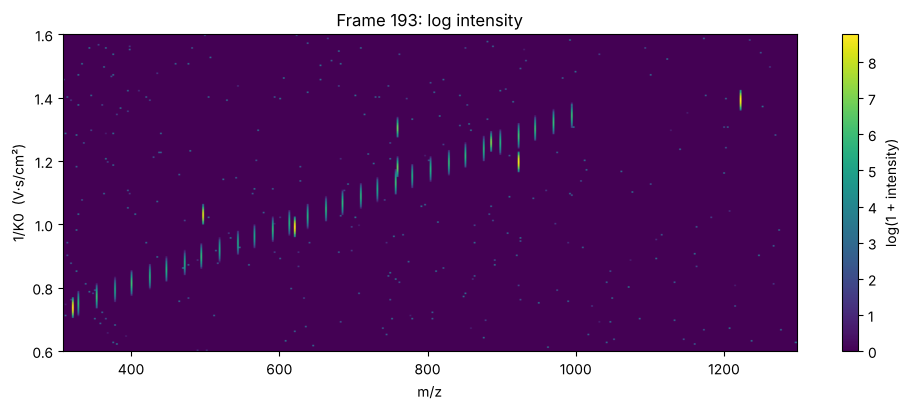

In [4]:
import matplotlib.pyplot as plt

fid = meta.frame_ids()[len(tdf) // 2]
mz, k0, inten = tdf.frame_mz_mobility(fid)
print(f"frame {fid}: {mz.size} peaks, m/z {mz.min():.1f}-{mz.max():.1f}, "
      f"1/K0 {k0.min():.3f}-{k0.max():.3f}")

H, xe, ye = np.histogram2d(mz, k0, bins=[400, 200], weights=inten)
fig, ax = plt.subplots(figsize=(10, 4.2))
im = ax.imshow(np.log1p(H.T), origin="lower", aspect="auto",
               extent=[xe[0], xe[-1], ye[0], ye[-1]], cmap="viridis")
ax.set_xlabel("m/z"); ax.set_ylabel("1/K0  (V·s/cm²)")
ax.set_title(f"Frame {fid}: log intensity")
plt.colorbar(im, ax=ax, label="log(1 + intensity)")
plt.tight_layout(); plt.show()

## 4. Extracted ion mobilogram, and an isobaric pair

Pick an m/z window and sum intensity per scan across frames: that is the ion's mobilogram.
Two species at the same m/z but different 1/K0 show up as two peaks — invisible in a plain
mass spectrum, separated here. CCS follows from 1/K0 by the Mason-Schamp equation.

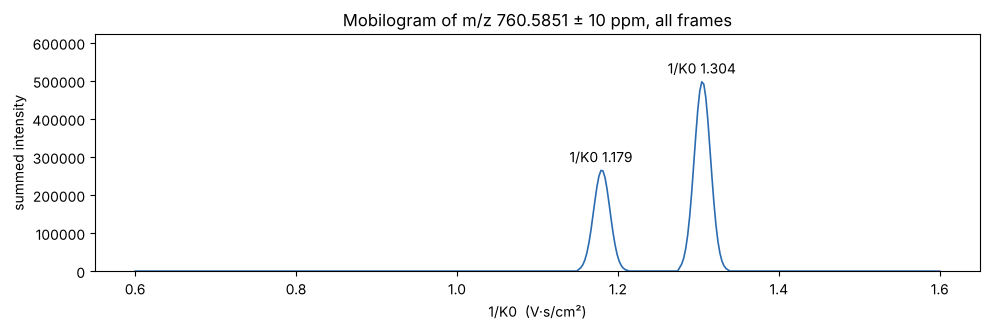

2 mobility peak(s) at m/z 760.5851:
  1/K0 = 1.3043   CCS (z=1, N2, 305 K) = 265.9 Å²   intensity 497,604
  1/K0 = 1.1790   CCS (z=1, N2, 305 K) = 240.4 Å²   intensity 264,655


In [5]:
def mobilogram(tdf, target_mz, ppm, frame_ids=None):
    """Summed intensity per scan for peaks within +/- ppm of target_mz."""
    lo, hi = target_mz * (1 - ppm * 1e-6), target_mz * (1 + ppm * 1e-6)
    idx_lo, idx_hi = tdf.mz_to_index([lo, hi])
    acc = np.zeros(tdf.meta.num_scans)
    for fid in (frame_ids or tdf.meta.frame_ids()):
        fr = tdf.read_frame(fid)
        m = (fr.tof_indices >= idx_lo) & (fr.tof_indices <= idx_hi)
        np.add.at(acc, fr.scan[m], fr.intensities[m])
    return acc


def mobility_peaks(profile, k0_axis, min_rel_height=0.2):
    """Local maxima of a mobilogram above a fraction of its highest point."""
    peaks = []
    thr = profile.max() * min_rel_height
    for s in range(1, profile.size - 1):
        if profile[s] >= thr and profile[s] >= profile[s - 1] and profile[s] > profile[s + 1]:
            peaks.append(s)
    return [(k0_axis[s], profile[s]) for s in peaks]


scans = np.arange(meta.num_scans)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")          # extrapolation notice at the scan ends
    k0_axis = tdf.scan_to_oneoverk0(scans)

eim = mobilogram(tdf, TARGET_MZ, PPM_WINDOW)
found = mobility_peaks(eim, k0_axis)

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(k0_axis, eim, lw=1.2, color="#2b6cb0")
for k, h in found:
    ax.annotate(f"1/K0 {k:.3f}", (k, h), textcoords="offset points", xytext=(0, 6), ha="center")
ax.set_xlabel("1/K0  (V·s/cm²)"); ax.set_ylabel("summed intensity"); ax.set_ylim(0, eim.max() * 1.25)
ax.set_title(f"Mobilogram of m/z {TARGET_MZ} ± {PPM_WINDOW:g} ppm, all frames")
plt.tight_layout(); plt.show()

print(f"{len(found)} mobility peak(s) at m/z {TARGET_MZ}:")
for k, h in found:
    ccs = tdf.oneoverk0_to_ccs(k, TARGET_MZ, charge=1)
    print(f"  1/K0 = {k:.4f}   CCS (z=1, N2, 305 K) = {ccs:.1f} Å²   intensity {h:,.0f}")

## 5. Mass spectra: mobility-integrated and mobility-filtered

Summing every scan gives the ordinary mass spectrum. Summing only scans within a 1/K0
window gives a spectrum of just the ions that elute there — a clean way to pull one
species out of a crowded region, and the basis of the mobility-filtered ion images below.

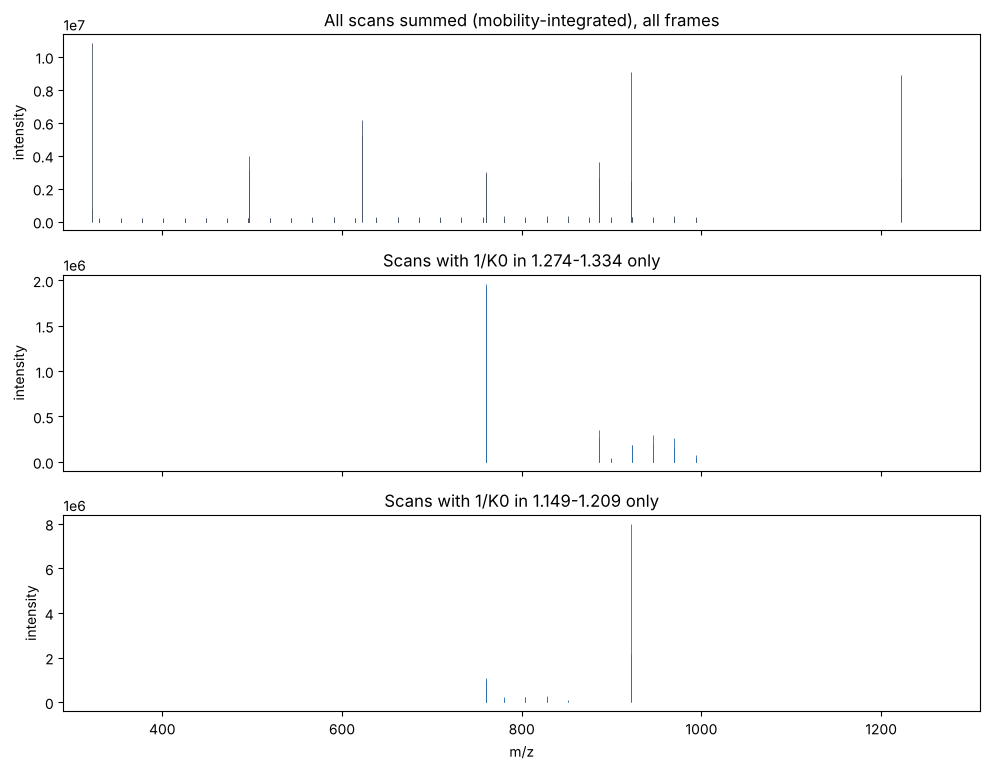

In [6]:
def summed_spectrum(tdf, frame_ids=None, k0_window=None):
    """Mobility-integrated centroid spectrum: peaks with the same TOF index are
    merged across scans (and frames). Returns (m/z, intensity) sorted by m/z."""
    scan_lo, scan_hi = 0, tdf.meta.num_scans - 1
    if k0_window is not None:
        # 1/K0 falls with scan number, so the window's high end is the low scan
        s = tdf.oneoverk0_to_scan(list(k0_window))
        scan_lo, scan_hi = int(np.floor(min(s))), int(np.ceil(max(s)))
    acc = {}
    for fid in (frame_ids or tdf.meta.frame_ids()):
        fr = tdf.read_frame(fid)
        m = (fr.scan >= scan_lo) & (fr.scan <= scan_hi)
        tof, inten = fr.tof_indices[m], fr.intensities[m]
        u, inv = np.unique(tof, return_inverse=True)
        sums = np.bincount(inv, weights=inten)
        for t, v in zip(u, sums):
            acc[int(t)] = acc.get(int(t), 0.0) + float(v)
    tof = np.array(sorted(acc), dtype=np.float64)
    return tdf.index_to_mz(tof), np.array([acc[int(t)] for t in tof])


with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    mz_all, int_all = summed_spectrum(tdf)
    windows = [(k - 0.03, k + 0.03) for k, _ in found[:2]]
    filtered = [summed_spectrum(tdf, k0_window=w) for w in windows]

fig, axes = plt.subplots(1 + len(filtered), 1, figsize=(10, 2.6 * (1 + len(filtered))), sharex=True)
axes = np.atleast_1d(axes)
axes[0].vlines(mz_all, 0, int_all, lw=0.6, color="#4a5568")
axes[0].set_title("All scans summed (mobility-integrated), all frames")
for ax, (w, (m, i)) in zip(axes[1:], zip(windows, filtered)):
    ax.vlines(m, 0, i, lw=0.6, color="#2b6cb0")
    ax.set_title(f"Scans with 1/K0 in {w[0]:.3f}-{w[1]:.3f} only")
axes[-1].set_xlabel("m/z")
for ax in axes: ax.set_ylabel("intensity"); ax.margins(x=0.01)
plt.tight_layout(); plt.show()

## 6. MALDI imaging: ion images with and without a mobility window

Pixel positions come from `MaldiFrameInfo`, the table imaging acquisitions carry alongside
the documented core schema. For the target m/z, the image on the left sums all mobility
scans, as any non-TIMS instrument would; the ones on the right keep only the scans around
each mobility peak found in section 4. On the demo data the two isobars have different
distributions, so the mobility-filtered images differ from each other and from their sum.

(If your dataset is not an imaging run, this section is skipped.)

384 pixels on a 24 x 16 grid


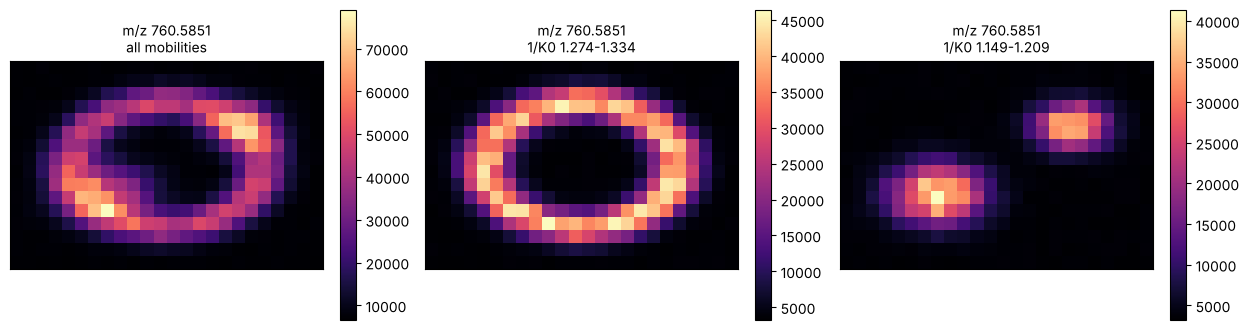

In [7]:
if meta.is_maldi:
    rows = meta.table("MaldiFrameInfo")
    coords = {r["Frame"]: (r["XIndexPos"], r["YIndexPos"]) for r in rows}
    xs = np.array([c[0] for c in coords.values()]); ys = np.array([c[1] for c in coords.values()])
    x0, y0 = xs.min(), ys.min()
    W, Hh = xs.max() - x0 + 1, ys.max() - y0 + 1
    print(f"{len(coords)} pixels on a {W} x {Hh} grid")

    def ion_image(target_mz, ppm, k0_window=None):
        lo, hi = target_mz * (1 - ppm * 1e-6), target_mz * (1 + ppm * 1e-6)
        idx_lo, idx_hi = tdf.mz_to_index([lo, hi])
        scan_lo, scan_hi = 0, meta.num_scans - 1
        if k0_window is not None:
            s = tdf.oneoverk0_to_scan(list(k0_window))
            scan_lo, scan_hi = int(np.floor(min(s))), int(np.ceil(max(s)))
        img = np.full((Hh, W), np.nan)
        for fid, (x, y) in coords.items():
            fr = tdf.read_frame(fid)
            m = ((fr.tof_indices >= idx_lo) & (fr.tof_indices <= idx_hi)
                 & (fr.scan >= scan_lo) & (fr.scan <= scan_hi))
            img[y - y0, x - x0] = fr.intensities[m].sum()
        return img

    panels = [("all mobilities", None)] + [(f"1/K0 {w[0]:.3f}-{w[1]:.3f}", w) for w in windows]
    fig, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 3.4))
    for ax, (title, w) in zip(np.atleast_1d(axes), panels):
        img = ion_image(TARGET_MZ, PPM_WINDOW, w)
        im = ax.imshow(img, origin="lower", cmap="magma", interpolation="nearest")
        ax.set_title(f"m/z {TARGET_MZ}\n{title}", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
        plt.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout(); plt.show()
else:
    print("Not an imaging dataset (no MaldiFrameInfo table); skipping.")

## 7. Export to imzML

imzML has no mobility dimension, so each pixel gets a *mobility-integrated* centroid
spectrum (every scan summed), which is what imaging software expects. To export only the
ions in a mobility window instead — one isobar, not both — set `EXPORT_K0_WINDOW`.
Writing uses [pyimzML](https://github.com/alexandrovteam/pyimzML); the result opens in
SCiLS, Cardinal, METASPACE and MSiReader.

For a non-imaging run this writes one spectrum per frame on a 1 × N "grid", which is a
legitimate way to hand the frames to imzML-reading tools.

In [8]:
import time
from pyimzml.ImzMLWriter import ImzMLWriter

EXPORT_K0_WINDOW = None            # e.g. (1.15, 1.21) to export one mobility band only
MZ_RANGE = None                    # e.g. (300, 1300) to trim the m/z axis
MIN_INTENSITY = None               # e.g. 20 to drop the noise floor

OUTPUT_IMZML.parent.mkdir(parents=True, exist_ok=True)
polarity = {"+": "positive", "-": "negative"}.get(first.polarity)
if meta.is_maldi:
    pixels = sorted(coords.items())                      # (frame, (x, y))
    pixels = [(fid, (x - x0 + 1, y - y0 + 1)) for fid, (x, y) in pixels]
else:
    pixels = [(fid, (i + 1, 1)) for i, fid in enumerate(meta.frame_ids())]

t0 = time.time(); n_written = 0; n_peaks = 0
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    with ImzMLWriter(str(OUTPUT_IMZML), mode="processed", spec_type="centroid",
                     polarity=polarity) as writer:
        for fid, (x, y) in pixels:
            mz, inten = summed_spectrum(tdf, [fid], EXPORT_K0_WINDOW)
            if MZ_RANGE is not None:
                keep = (mz >= MZ_RANGE[0]) & (mz <= MZ_RANGE[1]); mz, inten = mz[keep], inten[keep]
            if MIN_INTENSITY is not None:
                keep = inten >= MIN_INTENSITY; mz, inten = mz[keep], inten[keep]
            if mz.size == 0:
                continue
            writer.addSpectrum(mz, inten, (x, y))
            n_written += 1; n_peaks += mz.size

print(f"wrote {n_written} spectra, {n_peaks:,} peaks, in {time.time() - t0:.1f} s")
print(f"-> {OUTPUT_IMZML}  +  {OUTPUT_IMZML.with_suffix('.ibd').name}")

wrote 384 spectra, 143,020 peaks, in 0.3 s
-> out/converted_tims.imzML  +  converted_tims.ibd


In [9]:
# Verify: read it back and compare a few spectra with the source
from pyimzml.ImzMLParser import ImzMLParser

parser = ImzMLParser(str(OUTPUT_IMZML))
assert len(parser.coordinates) == n_written, "spectrum count mismatch"
check = [0, len(parser.coordinates) // 2, len(parser.coordinates) - 1]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for k in check:
        mz_i, int_i = parser.getspectrum(k)
        fid = pixels[k][0]
        mz_t, int_t = summed_spectrum(tdf, [fid], EXPORT_K0_WINDOW)
        if MZ_RANGE is not None:
            keep = (mz_t >= MZ_RANGE[0]) & (mz_t <= MZ_RANGE[1]); mz_t, int_t = mz_t[keep], int_t[keep]
        if MIN_INTENSITY is not None:
            keep = int_t >= MIN_INTENSITY; mz_t, int_t = mz_t[keep], int_t[keep]
        assert np.allclose(mz_i, mz_t) and np.allclose(int_i, int_t), f"spectrum {k} differs"
print(f"verified {len(check)} spectra against the source: identical")

tdf.close()

verified 3 spectra against the source: identical


## Notes

**Intensities** are the values stored in the file, as timsrust and OpenTIMS also return.
Bruker's library returns them multiplied by a per-file factor that is not documented
(see the README); relative intensities are unaffected.

**Mobility accuracy.** Section 2's table is the thing to look at. If the mobility line says
`acquisition_range approximation`, no usable calibrant ions were found in the data and 1/K0 is
only good to a few percent. The fix is upstream — acquire with calibrant present — or, if
you know ions of established 1/K0 in your sample, calibrate on them:

```python
from pytsf import MobilityCalibration, find_reference_ions
ions = find_reference_ions(tdf, mz_list=[...], oneoverk0_list=[...], ppm=10)
cal = MobilityCalibration.from_reference_ions([i.apex_scan for i in ions if i.found],
                                              [i.oneoverk0 for i in ions if i.found],
                                              tdf.meta.num_scans, reference_ions=ions)
tdf = TdfData(ANALYSIS_DIR, mobility=cal)
```

**PASEF runs.** `meta.pasef_msms_info(frame_id)` and `meta.precursors()` expose the
`PasefFrameMsMsInfo` and `Precursors` tables from Bruker's documented schema as rows; an
MS/MS frame's peaks within `ScanNumBegin..ScanNumEnd` are the fragment spectrum of that
isolation window. MS/MS frames have `msms_type != 0` and are not summed into the spectra
above unless you pass them explicitly.

**Speed.** Everything here is NumPy over one frame at a time. A 1,000-pixel MALDI-TIMS
imaging run reads in well under a minute; the per-ion functions (`mobilogram`, `ion_image`)
re-read the frames each call, so for many ions it is faster to read each frame once and
accumulate all targets in the same pass.